In [1]:
import sys
import pandas as pd
import numpy as np

print("Python version:", sys.version)
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("GridSense environment is ready!")

from pathlib import Path
import pandas as pd

# Dataset ka path
DATA_PATH = Path("../data/raw/PJME_hourly.csv")

# CSV load karna
df = pd.read_csv(DATA_PATH)

# Basic information
print("Dataset successfully loaded!")
print("-" * 40)
print("Rows and columns:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

Python version: 3.13.3 (tags/v3.13.3:6280bb5, Apr  8 2025, 14:47:33) [MSC v.1943 64 bit (AMD64)]
Pandas version: 3.0.6
NumPy version: 2.5.4
GridSense environment is ready!
Dataset successfully loaded!
----------------------------------------
Rows and columns: (145366, 2)

Column names:
['Datetime', 'PJME_MW']

First 5 rows:


,Datetime,PJME_MW
0,2002-12-31 01:00:00,26498.0
1,2002-12-31 02:00:00,25147.0
2,2002-12-31 03:00:00,24574.0
3,2002-12-31 04:00:00,24393.0
4,2002-12-31 05:00:00,24860.0


In [3]:
from pathlib import Path
import pandas as pd
import numpy as np

DATA_PATH = Path("../data/raw/PJME_hourly.csv")

df = pd.read_csv(DATA_PATH)
df["Datetime"] = pd.to_datetime(df["Datetime"], errors="coerce")

print("Dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Shape: (145366, 2)


,Datetime,PJME_MW
0,2002-12-31 01:00:00,26498.0
1,2002-12-31 02:00:00,25147.0
2,2002-12-31 03:00:00,24574.0
3,2002-12-31 04:00:00,24393.0
4,2002-12-31 05:00:00,24860.0


In [2]:

# 1. Dataset ka structure aur data types
print("DATASET INFO")
print("=" * 50)
df.info()

# 2. Missing values
print("\nMISSING VALUES")
print("=" * 50)
print(df.isnull().sum())

# 3. Duplicate rows
print("\nDUPLICATE ROWS")
print("=" * 50)
print("Duplicate rows:", df.duplicated().sum())

# 4. Statistical summary
print("\nSTATISTICAL SUMMARY")
print("=" * 50)
display(df.describe())


DATASET INFO
<class 'pandas.DataFrame'>
RangeIndex: 145366 entries, 0 to 145365
Data columns (total 2 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   Datetime  145366 non-null  str    
 1   PJME_MW   145366 non-null  float64
dtypes: float64(1), str(1)
memory usage: 2.2 MB

MISSING VALUES
Datetime    0
PJME_MW     0
dtype: int64

DUPLICATE ROWS
Duplicate rows: 0

STATISTICAL SUMMARY


,PJME_MW
count,145366.000000
mean,32080.222831
std,6464.012166
min,14544.000000
25%,27573.000000
50%,31421.000000
75%,35650.000000
max,62009.000000


In [3]:

# Column names ko dekhkar timestamp column identify karna
print("Columns:", df.columns.tolist())

# Expected timestamp column
df["Datetime"] = pd.to_datetime(df["Datetime"], errors="coerce")

print("\nDate range:")
print("Start:", df["Datetime"].min())
print("End:  ", df["Datetime"].max())

print("\nInvalid timestamps:", df["Datetime"].isna().sum())
print("Duplicate timestamps:", df["Datetime"].duplicated().sum())

# Time ke order mein arrange karna
df = df.sort_values("Datetime").reset_index(drop=True)

print("\nFirst 5 sorted records:")
display(df.head())


Columns: ['Datetime', 'PJME_MW']

Date range:
Start: 2002-01-01 01:00:00
End:   2018-08-03 00:00:00

Invalid timestamps: 0
Duplicate timestamps: 4

First 5 sorted records:


,Datetime,PJME_MW
0,2002-01-01 01:00:00,30393.0
1,2002-01-01 02:00:00,29265.0
2,2002-01-01 03:00:00,28357.0
3,2002-01-01 04:00:00,27899.0
4,2002-01-01 05:00:00,28057.0


In [4]:

# Consecutive timestamps ke beech ka gap
time_gaps = df["Datetime"].diff()

print("Time gap counts:")
display(time_gaps.value_counts().head(10))

# One-hour se bade gaps
large_gaps = df.loc[
    time_gaps > pd.Timedelta(hours=1),
    ["Datetime"]
].copy()

large_gaps["Gap"] = time_gaps[time_gaps > pd.Timedelta(hours=1)]

print("\nGaps larger than 1 hour:", len(large_gaps))
display(large_gaps.head(10))


Time gap counts:


Datetime
0 days 01:00:00    145331
0 days 02:00:00        30
0 days 00:00:00         4
Name: count, dtype: int64


Gaps larger than 1 hour: 30


,Datetime,Gap
2306,2002-04-07 04:00:00,0 days 02:00:00
7176,2002-10-27 03:00:00,0 days 02:00:00
11040,2003-04-06 04:00:00,0 days 02:00:00
15910,2003-10-26 03:00:00,0 days 02:00:00
19774,2004-04-04 04:00:00,0 days 02:00:00
24812,2004-10-31 03:00:00,0 days 02:00:00
28508,2005-04-03 04:00:00,0 days 02:00:00
33546,2005-10-30 03:00:00,0 days 02:00:00
37242,2006-04-02 04:00:00,0 days 02:00:00
42280,2006-10-29 03:00:00,0 days 02:00:00


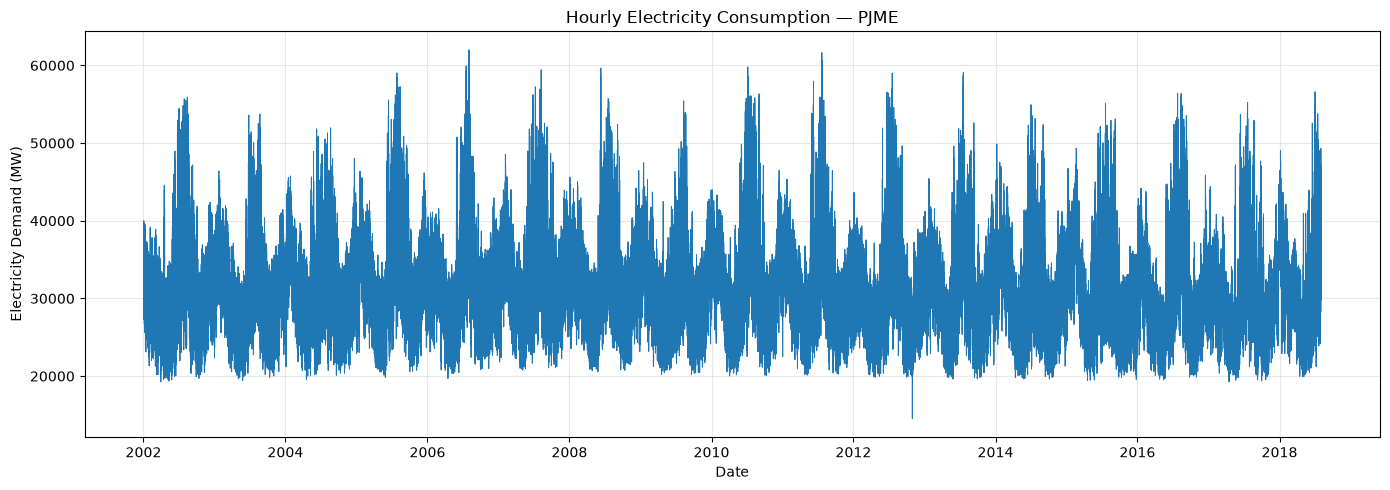

In [5]:

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))
plt.plot(df["Datetime"], df["PJME_MW"], linewidth=0.7)

plt.title("Hourly Electricity Consumption — PJME")
plt.xlabel("Date")
plt.ylabel("Electricity Demand (MW)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [4]:
# Ensure data is sorted by time
df = df.sort_values("Datetime").copy()

# Extract time-based features
df["Hour"] = df["Datetime"].dt.hour
df["DayOfWeek"] = df["Datetime"].dt.dayofweek
df["DayName"] = df["Datetime"].dt.day_name()
df["Month"] = df["Datetime"].dt.month

display(df[["Datetime", "PJME_MW", "Hour", "DayName", "Month"]].head(10))

,Datetime,PJME_MW,Hour,DayName,Month
8734,2002-01-01 01:00:00,30393.0,1,Tuesday,1
8735,2002-01-01 02:00:00,29265.0,2,Tuesday,1
8736,2002-01-01 03:00:00,28357.0,3,Tuesday,1
8737,2002-01-01 04:00:00,27899.0,4,Tuesday,1
8738,2002-01-01 05:00:00,28057.0,5,Tuesday,1
8739,2002-01-01 06:00:00,28654.0,6,Tuesday,1
8740,2002-01-01 07:00:00,29308.0,7,Tuesday,1
8741,2002-01-01 08:00:00,29595.0,8,Tuesday,1
8742,2002-01-01 09:00:00,29943.0,9,Tuesday,1
8743,2002-01-01 10:00:00,30692.0,10,Tuesday,1


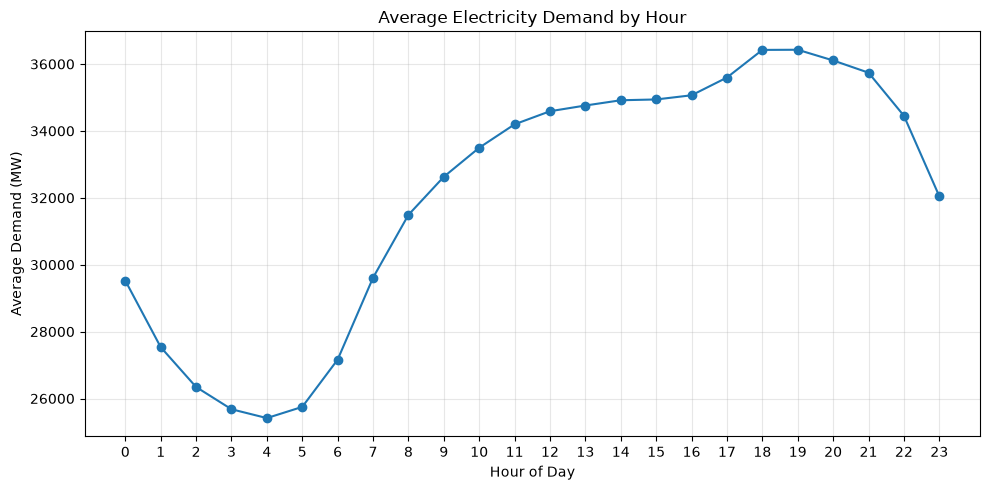

In [5]:
import matplotlib.pyplot as plt

hourly_demand = df.groupby("Hour")["PJME_MW"].mean()

plt.figure(figsize=(10, 5))
hourly_demand.plot(marker="o")
plt.title("Average Electricity Demand by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Demand (MW)")
plt.xticks(range(24))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

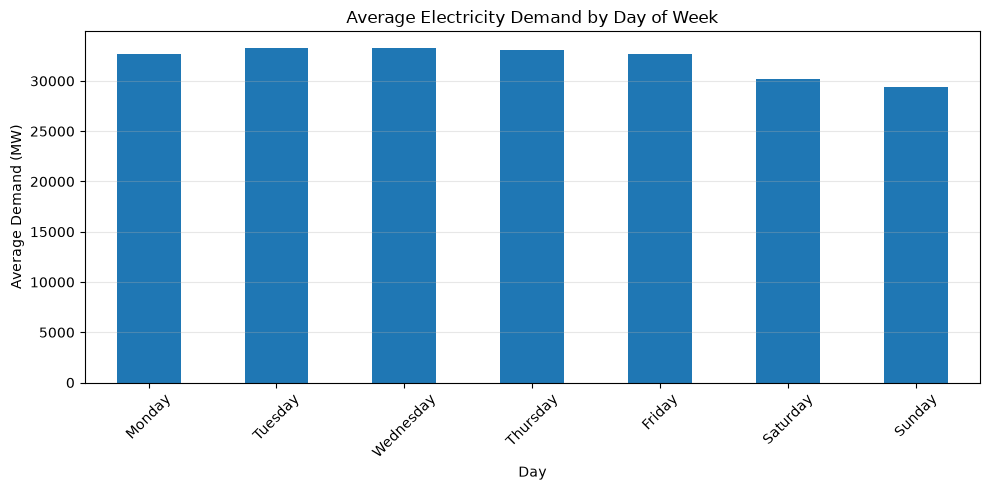

In [6]:
weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekday_demand = (
    df.groupby("DayName")["PJME_MW"]
      .mean()
      .reindex(weekday_order)
)

plt.figure(figsize=(10, 5))
weekday_demand.plot(kind="bar")
plt.title("Average Electricity Demand by Day of Week")
plt.xlabel("Day")
plt.ylabel("Average Demand (MW)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [7]:

import numpy as np
import matplotlib.pyplot as plt

# Work on a time-sorted copy
analysis_df = df.sort_values("Datetime").copy()
analysis_df = analysis_df.dropna(subset=["Datetime", "PJME_MW"])

# Rolling baseline using the previous 24 hours
analysis_df["Rolling_Median"] = (
    analysis_df["PJME_MW"]
    .shift(1)
    .rolling(window=24, min_periods=24)
    .median()
)

# Rolling Median Absolute Deviation (MAD)
analysis_df["Rolling_MAD"] = (
    (analysis_df["PJME_MW"] - analysis_df["Rolling_Median"])
    .abs()
    .shift(1)
    .rolling(window=24, min_periods=24)
    .median()
)

# Robust anomaly score
analysis_df["Anomaly_Score"] = (
    (analysis_df["PJME_MW"] - analysis_df["Rolling_Median"])
    .abs()
    / (1.4826 * analysis_df["Rolling_MAD"].replace(0, np.nan))
)

# Initial threshold; this is a screening rule, not ground truth
analysis_df["Potential_Anomaly"] = (
    analysis_df["Anomaly_Score"] > 3.5
)

print("Potential anomaly flags:", analysis_df["Potential_Anomaly"].sum())


Potential anomaly flags: 5061


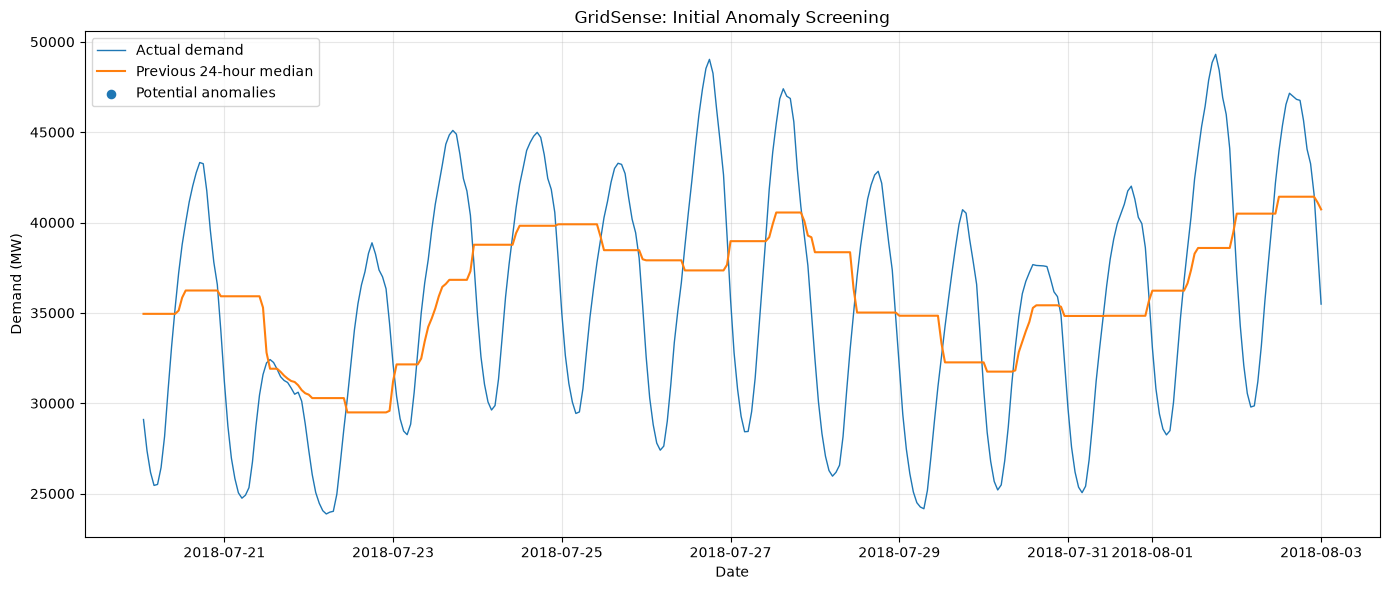

In [9]:

# Show the latest 14 days of available data
plot_df = analysis_df.dropna(subset=["Rolling_Median"]).tail(24 * 14)
anomalies = plot_df[plot_df["Potential_Anomaly"]]

plt.figure(figsize=(14, 6))
plt.plot(
    plot_df["Datetime"],
    plot_df["PJME_MW"],
    label="Actual demand",
    linewidth=1
)
plt.plot(
    plot_df["Datetime"],
    plot_df["Rolling_Median"],
    label="Previous 24-hour median",
    linewidth=1.5
)
plt.scatter(
    anomalies["Datetime"],
    anomalies["PJME_MW"],
    label="Potential anomalies",
    s=35
)

plt.title("GridSense: Initial Anomaly Screening")
plt.xlabel("Date")
plt.ylabel("Demand (MW)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [2]:

from pathlib import Path
import pandas as pd
import numpy as np

# 1. Load the dataset
DATA_PATH = Path("../data/raw/PJME_hourly.csv")
df = pd.read_csv(DATA_PATH)
df["Datetime"] = pd.to_datetime(df["Datetime"], errors="coerce")

# 2. Prepare time-series data
analysis_df = (
    df.dropna(subset=["Datetime", "PJME_MW"])
      .sort_values("Datetime")
      .copy()
)

# 3. Calculate previous 24-hour rolling median
analysis_df["Rolling_Median"] = (
    analysis_df["PJME_MW"]
    .shift(1)
    .rolling(window=24, min_periods=24)
    .median()
)

# 4. Calculate rolling MAD
deviations = (
    analysis_df["PJME_MW"] - analysis_df["Rolling_Median"]
).abs()

analysis_df["Rolling_MAD"] = (
    deviations.shift(1)
    .rolling(window=24, min_periods=24)
    .median()
)

# 5. Calculate anomaly score
scale = 1.4826 * analysis_df["Rolling_MAD"]
analysis_df["Anomaly_Score"] = (
    (analysis_df["PJME_MW"] - analysis_df["Rolling_Median"]).abs()
    / scale.replace(0, np.nan)
)

analysis_df["Potential_Anomaly"] = (
    analysis_df["Anomaly_Score"] > 3.5
).fillna(False)

# 6. Review results
print("Total observations:", len(analysis_df))
print("Potential anomalies:", int(analysis_df["Potential_Anomaly"].sum()))

anomaly_review = (
    analysis_df.loc[
        analysis_df["Potential_Anomaly"],
        ["Datetime", "PJME_MW", "Rolling_Median",
         "Rolling_MAD", "Anomaly_Score"]
    ]
    .sort_values("Anomaly_Score", ascending=False)
)

display(anomaly_review.head(15))


Total observations: 145366
Potential anomalies: 5061


,Datetime,PJME_MW,Rolling_Median,Rolling_MAD,Anomaly_Score
102243,2013-05-02 04:00:00,21172.0,28845.5,241.25,21.453699
102242,2013-05-02 03:00:00,21218.0,28845.5,241.25,21.325091
102241,2013-05-02 02:00:00,21640.0,28845.5,241.25,20.145257
102244,2013-05-02 05:00:00,21744.0,28845.5,241.25,19.854492
66588,2009-05-27 04:00:00,21476.0,30829.5,355.50,17.746412
102240,2013-05-02 01:00:00,22552.0,28845.5,241.25,17.595472
66587,2009-05-27 03:00:00,21639.0,30829.5,355.50,17.437151
66589,2009-05-27 05:00:00,21880.0,30829.5,355.50,16.979902
66586,2009-05-27 02:00:00,22171.0,30829.5,355.50,16.427787
102411,2013-04-25 04:00:00,21280.0,29629.0,361.00,15.599234


In [4]:

import pandas as pd
import numpy as np

# Reload data so this cell works even after a kernel restart
DATA_PATH = "../data/raw/PJME_hourly.csv"

df = pd.read_csv(DATA_PATH)
df["Datetime"] = pd.to_datetime(df["Datetime"], errors="coerce")
df = (
    df.dropna(subset=["Datetime", "PJME_MW"])
      .sort_values("Datetime")
      .reset_index(drop=True)
)

# Time-based features
df["Hour"] = df["Datetime"].dt.hour
df["DayOfWeek"] = df["Datetime"].dt.dayofweek

# Same weekday + same hour, from previous weeks
df["Seasonal_Baseline"] = (
    df.groupby(["DayOfWeek", "Hour"])["PJME_MW"]
      .transform(lambda s: s.shift(1).rolling(4, min_periods=3).median())
)

# Robust deviation from the seasonal baseline
df["Seasonal_Deviation"] = (
    df["PJME_MW"] - df["Seasonal_Baseline"]
)

# Historical deviation scale, calculated without current observation
df["Historical_Abs_Deviation"] = (
    df.groupby(["DayOfWeek", "Hour"])["Seasonal_Deviation"]
      .transform(lambda s: s.abs().shift(1).rolling(4, min_periods=3).median())
)

scale = 1.4826 * df["Historical_Abs_Deviation"].replace(0, np.nan)

df["Seasonal_Anomaly_Score"] = (
    df["Seasonal_Deviation"].abs() / scale
)

df["Seasonal_Anomaly"] = (
    df["Seasonal_Anomaly_Score"] > 3.5
).fillna(False)

print("Total records:", len(df))
print("Seasonal potential anomalies:", int(df["Seasonal_Anomaly"].sum()))

display(
    df.loc[
        df["Seasonal_Anomaly"],
        ["Datetime", "PJME_MW", "Seasonal_Baseline",
         "Seasonal_Anomaly_Score"]
    ]
    .sort_values("Seasonal_Anomaly_Score", ascending=False)
    .head(15)
)


Total records: 145366
Seasonal potential anomalies: 8552


,Datetime,PJME_MW,Seasonal_Baseline,Seasonal_Anomaly_Score
38654,2006-05-31 00:00:00,35803.0,25492.5,213.979599
38674,2006-05-31 20:00:00,44146.0,31052.0,186.916021
38653,2006-05-30 23:00:00,40371.0,28353.0,177.180982
126259,2016-05-28 22:00:00,37943.0,26044.0,168.078860
47309,2007-05-26 17:00:00,39779.0,27519.0,143.190592
126258,2016-05-28 21:00:00,39086.0,26507.5,103.780820
38655,2006-05-31 01:00:00,32695.0,23520.5,93.759325
126260,2016-05-28 23:00:00,35133.0,24705.5,82.501494
2580,2002-04-18 14:00:00,43352.0,30579.5,81.658135
47310,2007-05-26 18:00:00,39537.0,27573.5,76.667650
